In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/raw/daily_usage_messy .csv", dtype=str, keep_default_na=False)
raw = df.copy()
print(df.shape)

(265311, 14)


In [2]:
print(list(df.columns))
df.sample(10, random_state=1)

['record_id', 'user_id', 'date', 'day_index', 'day_of_week', 'is_weekend', 'daily_screen_time_hours', 'social_media_hours', 'gaming_hours', 'work_study_hours', 'sleep_hours', 'notifications_per_day', 'app_opens_per_day', 'physical_activity_minutes']


,record_id,user_id,date,day_index,day_of_week,is_weekend,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,physical_activity_minutes
159642,R0138694,U04624,09-04-2026,4,Friday,0,3.33,0.36,0.92,1.84,8.85,86,171,82
149137,R0103836,U03462,2026-09-06,6,Sunday,1,10.48,2.67,2.8,1.14,5.0,239,51,47
97701,R0077508,U02584,2026-09-18,18,Friday,0,8.31,3.85,2.47,1.41,7.92,194,57,6
189728,R0067578,U02253,2026-09-18,18,FRIDAY,0,10.79,4.21,0.93,4.27,6.39,90,173,23
230923,R0016820,U00561,2026-09-20,20,Sunday,1,7.45,3.3,3.23,0.69,7.17,59,115,83
76116,R0199600,U06654,2026-09-10,10,Thursday,0,10.95,1.33,0.16,5.46,6.11,254,60,24
65880,R0207167,U06906,2026-09-17,17,Thursday,0,10.22,3.14,2.96,3.48,5.88,118,66,null
168174,R0201968,U06733,2026-09-08,8,Tuesday,0,4.7,1.48,1.52,NaN,9.19,71,113,35
2494,R0084794,U02827,14 Sep 2026,14,Monday,0,8.38,2.77,0.49,4.53,8.3,42,144,42
9559,R0081549,U02719,09-09-2026,9,Wednesday,0,6.75,2.52,1.94,1.6,4.86,259,39,15


In [3]:
print(df.nunique())

record_id                    261390
user_id                       10258
date                            150
day_index                        30
day_of_week                      35
is_weekend                        2
daily_screen_time_hours        2390
social_media_hours             6268
gaming_hours                    858
work_study_hours                858
sleep_hours                    1656
notifications_per_day           402
app_opens_per_day               287
physical_activity_minutes       178
dtype: int64


In [4]:
print("fully identical rows:", df.duplicated().sum())
print("repeated record_id:", df.duplicated(subset="record_id").sum())

fully identical rows: 3921
repeated record_id: 3921


In [5]:
for col in df.columns:
    print(col, "->", df[col].value_counts().head(5).to_dict())

record_id -> {'R0127161': 2, 'R0232289': 2, 'R0028048': 2, 'R0232488': 2, 'R0120848': 2}
user_id -> {'U00285': 35, 'U01896': 34, 'U02382': 34, 'U01769': 34, 'U05201': 34}
date -> {'2026-09-02': 6723, '2026-09-03': 6696, '2026-09-07': 6681, '2026-09-10': 6677, '2026-09-25': 6663}
day_index -> {'14': 8862, '23': 8861, '19': 8857, '15': 8856, '24': 8855}
day_of_week -> {'Wednesday': 40736, 'Tuesday': 40683, 'Saturday': 32656, 'Monday': 32551, 'Sunday': 32550}
is_weekend -> {'0': 194575, '1': 70736}
daily_screen_time_hours -> {'n/a': 483, 'NaN': 483, '': 470, 'None': 448, '-': 442}
social_media_hours -> {'1.54': 835, '1.49': 825, '1.41': 820, '1.53': 818, '1.27': 811}
gaming_hours -> {'1.01': 1015, '0.86': 1013, '0.95': 1007, '0.81': 1002, '0.98': 996}
work_study_hours -> {'1.09': 1019, '1.33': 995, '1.19': 988, '0.74': 987, '1.23': 981}
sleep_hours -> {'7.72': 638, '5.95': 636, '7.02': 629, '7.44': 623, '6.09': 622}
notifications_per_day -> {'32': 1282, '36': 1278, '27': 1254, '29': 1250,

In [6]:
num_cols = ["daily_screen_time_hours", "social_media_hours", "gaming_hours", "work_study_hours",
            "sleep_hours", "notifications_per_day", "app_opens_per_day",
            "physical_activity_minutes"]

for col in num_cols:
    as_number = pd.to_numeric(df[col], errors="coerce")
    n_text = as_number.isna().sum()
    print(col, "-> values that are not numbers:", n_text)
    print(df.loc[as_number.isna(), col].value_counts().head(6).to_dict())
    print()

daily_screen_time_hours -> values that are not numbers: 4765
{'n/a': 483, 'NaN': 483, '': 470, 'None': 448, '-': 442, 'NA': 432}

social_media_hours -> values that are not numbers: 3180
{'None': 484, '': 477, 'n/a': 470, 'null': 449, '-': 448, 'NA': 435}

gaming_hours -> values that are not numbers: 3188
{'null': 482, 'n/a': 473, '-': 473, 'NA': 458, 'NaN': 449, 'None': 439}

work_study_hours -> values that are not numbers: 3173
{'-': 472, 'None': 462, 'NaN': 461, 'null': 454, '': 450, 'n/a': 447}

sleep_hours -> values that are not numbers: 4777
{'NA': 486, 'NaN': 459, 'n/a': 455, 'null': 455, 'None': 451, '-': 447}

notifications_per_day -> values that are not numbers: 3176
{'None': 489, 'null': 475, '-': 457, 'NaN': 452, 'n/a': 449, '': 434}

app_opens_per_day -> values that are not numbers: 3184
{'': 498, '-': 479, 'NA': 472, 'null': 449, 'None': 448, 'n/a': 444}

physical_activity_minutes -> values that are not numbers: 3192
{'null': 472, 'NaN': 472, '-': 460, 'None': 458, 'NA': 4

In [7]:
null_words = ["", "nan", "n/a", "na", "-", "null", "none"]

for col in ["daily_screen_time_hours", "sleep_hours"]:
    text = df[col].str.strip()
    is_blank = text.str.lower().isin(null_words)
    not_number = pd.to_numeric(text, errors="coerce").isna()
    odd = not_number & ~is_blank
    print(col, "odd text values:", odd.sum())
    print(text[odd].sample(8, random_state=1).tolist())
    print()

daily_screen_time_hours odd text values: 1590
['8.97 hrs', '4.3 hrs', '6.99 hrs', '6.56 hrs', '5.75 hrs', '12.4 hrs', '6.93 hrs', '12.13 hrs']

sleep_hours odd text values: 1590
['7.46h', '4.84h', '7.19h', '5.4h', '7.21h', '8.05h', '6.35h', '6.63h']



In [8]:
nums = df[num_cols].apply(lambda c: pd.to_numeric(c.str.replace("[a-zA-Z ]", "", regex=True), errors="coerce"))
print(nums.describe().round(1).T[["count", "min", "50%", "max"]])

                              count   min    50%     max
daily_screen_time_hours    262136.0  -2.0    7.8    99.0
social_media_hours         262131.0   0.1    2.2    13.7
gaming_hours               262123.0   0.0    1.5    10.0
work_study_hours           262138.0   0.1    1.8     9.8
sleep_hours                262124.0  -3.0    6.8   627.0
notifications_per_day      262135.0 -50.0  131.0  9999.0
app_opens_per_day          262127.0 -10.0   95.0  5000.0
physical_activity_minutes  262119.0 -30.0   41.0  1500.0


In [9]:
df = df.drop_duplicates()
print("Duplicate rows:", df.duplicated().sum())
print("Dataset shape:", df.shape)

Duplicate rows: 0
Dataset shape: (261390, 14)


In [10]:
text_cols = list(df.columns)
for col in text_cols:
    df[col] = df[col].str.strip()

df[text_cols] = df[text_cols].replace(r"(?i)^(nan|n/a|na|-|null|none|)$", np.nan, regex=True)
print(df.isnull().sum()[df.isnull().sum() > 0])

daily_screen_time_hours      3136
social_media_hours           3136
gaming_hours                 3136
work_study_hours             3136
sleep_hours                  3136
notifications_per_day        3136
app_opens_per_day            3136
physical_activity_minutes    3136
dtype: int64


In [11]:
df["user_id"] = df["user_id"].str.strip().str.upper()
days_per_user = df["user_id"].value_counts()
print("Distinct user IDs:", len(days_per_user))
print(days_per_user.describe())
orphans = days_per_user[days_per_user < 20].index
print("IDs with fewer than 20 rows:", len(orphans))
print(list(orphans[:5]))

Distinct user IDs: 8972
count    8972.000000
mean       29.133972
std         4.852558
min         1.000000
25%        30.000000
50%        30.000000
75%        30.000000
max        30.000000
Name: count, dtype: float64
IDs with fewer than 20 rows: 259
['U95728', 'U95066', 'U95174', 'U93681', 'U94002']


In [12]:
df["block"] = (df["record_id"].str[1:].astype(int) - 1) // 30
valid = df[~df["user_id"].isin(orphans)]
users_per_block = valid.groupby("block")["user_id"].nunique()
print("Blocks:", df["block"].nunique())
print("Blocks that belong to exactly one valid user:", (users_per_block == 1).sum())

Blocks: 8713
Blocks that belong to exactly one valid user: 8713


In [13]:
owner = valid.groupby("block")["user_id"].agg(lambda s: s.mode()[0])
is_orphan = df["user_id"].isin(orphans)
df.loc[is_orphan, "user_id"] = df.loc[is_orphan, "block"].map(owner)
df = df.drop(columns="block")

print("Distinct user IDs:", df["user_id"].nunique())
print(df.groupby("user_id").size().describe())

Distinct user IDs: 8713
count    8713.0
mean       30.0
std         0.0
min        30.0
25%        30.0
50%        30.0
75%        30.0
max        30.0
dtype: float64


In [14]:
for col in num_cols:
    df[col] = pd.to_numeric(df[col].str.replace("[a-zA-Z ]", "", regex=True), errors="coerce")

for col in ["day_index", "is_weekend"]:
    df[col] = df[col].astype(int)

print(df[num_cols].dtypes)

daily_screen_time_hours      float64
social_media_hours           float64
gaming_hours                 float64
work_study_hours             float64
sleep_hours                  float64
notifications_per_day        float64
app_opens_per_day            float64
physical_activity_minutes    float64
dtype: object


In [15]:
in_minutes = df["sleep_hours"].between(120, 720)
print("Sleep values that are in minutes:", in_minutes.sum())
df.loc[in_minutes, "sleep_hours"] = df.loc[in_minutes, "sleep_hours"] / 60
print(df["sleep_hours"].describe().round(2))

Sleep values that are in minutes: 1568
count    258254.00
mean          6.87
std           2.05
min          -3.00
25%           5.69
50%           6.82
75%           7.97
max          48.00
Name: sleep_hours, dtype: float64


In [16]:
hours = ["daily_screen_time_hours", "social_media_hours", "gaming_hours", "work_study_hours", "sleep_hours"]
df[hours] = df[hours].round(2)
df[["notifications_per_day", "app_opens_per_day", "physical_activity_minutes"]] = \
    df[["notifications_per_day", "app_opens_per_day", "physical_activity_minutes"]].round(0)

In [17]:
pattern = df["date"].str.replace(r"\d", "9", regex=True).str.replace(r"[A-Za-z]", "a", regex=True)
print(pattern.value_counts())
print(df.groupby(pattern)["date"].first())

date
9999-99-99      196043
99/99/9999       26058
99 aaa 9999      16305
aaa 99, 9999     13306
99-99-9999        9678
Name: count, dtype: int64
date
99 aaa 9999      14 Sep 2026
99-99-9999        09-29-2026
99/99/9999        19/09/2026
9999-99-99        2026-09-09
aaa 99, 9999    Sep 13, 2026
Name: date, dtype: str


In [18]:
dashed = pattern == "99-99-9999"
for name, fmt in {"day-first": "%d-%m-%Y", "month-first": "%m-%d-%Y"}.items():
    parsed = pd.to_datetime(df.loc[dashed, "date"], format=fmt, errors="coerce")
    print(name, "-> can be read:", parsed.notna().mean().round(3),
          "| day matches day_index:", (parsed.dt.day == df.loc[dashed, "day_index"]).mean().round(3))

day-first -> can be read: 0.401 | day matches day_index: 0.034
month-first -> can be read: 1.0 | day matches day_index: 1.0


In [19]:
formats = {
    "9999-99-99":   "%Y-%m-%d",
    "99/99/9999":   "%d/%m/%Y",
    "99 aaa 9999":  "%d %b %Y",
    "aaa 99, 9999": "%b %d, %Y",
    "99-99-9999":   "%m-%d-%Y",
}
parts = [pd.to_datetime(df.loc[pattern == p, "date"], format=f) for p, f in formats.items()]
date = pd.concat(parts).reindex(df.index)

print("Start date:", date.min().date(), "| End date:", date.max().date())
print("Day of month equals day_index:", (date.dt.day == df["day_index"]).all())

Start date: 2026-09-01 | End date: 2026-09-30
Day of month equals day_index: True


In [20]:
dow_raw = df["day_of_week"].str.strip().str.title().replace(
    {"Mon": "Monday", "Tue": "Tuesday", "Wed": "Wednesday", "Thu": "Thursday",
     "Fri": "Friday", "Sat": "Saturday", "Sun": "Sunday"})
print("Raw day_of_week (after tidy-up) agrees with the date:", (dow_raw == date.dt.day_name()).mean().round(4))

df["date"] = date.dt.strftime("%Y-%m-%d")
df["day_of_week"] = date.dt.day_name()
df["is_weekend"] = (date.dt.dayofweek >= 5).astype(int)
print(df["day_of_week"].value_counts())

Raw day_of_week (after tidy-up) agrees with the date: 1.0
day_of_week
Wednesday    43565
Tuesday      43565
Friday       34852
Saturday     34852
Sunday       34852
Thursday     34852
Monday       34852
Name: count, dtype: int64


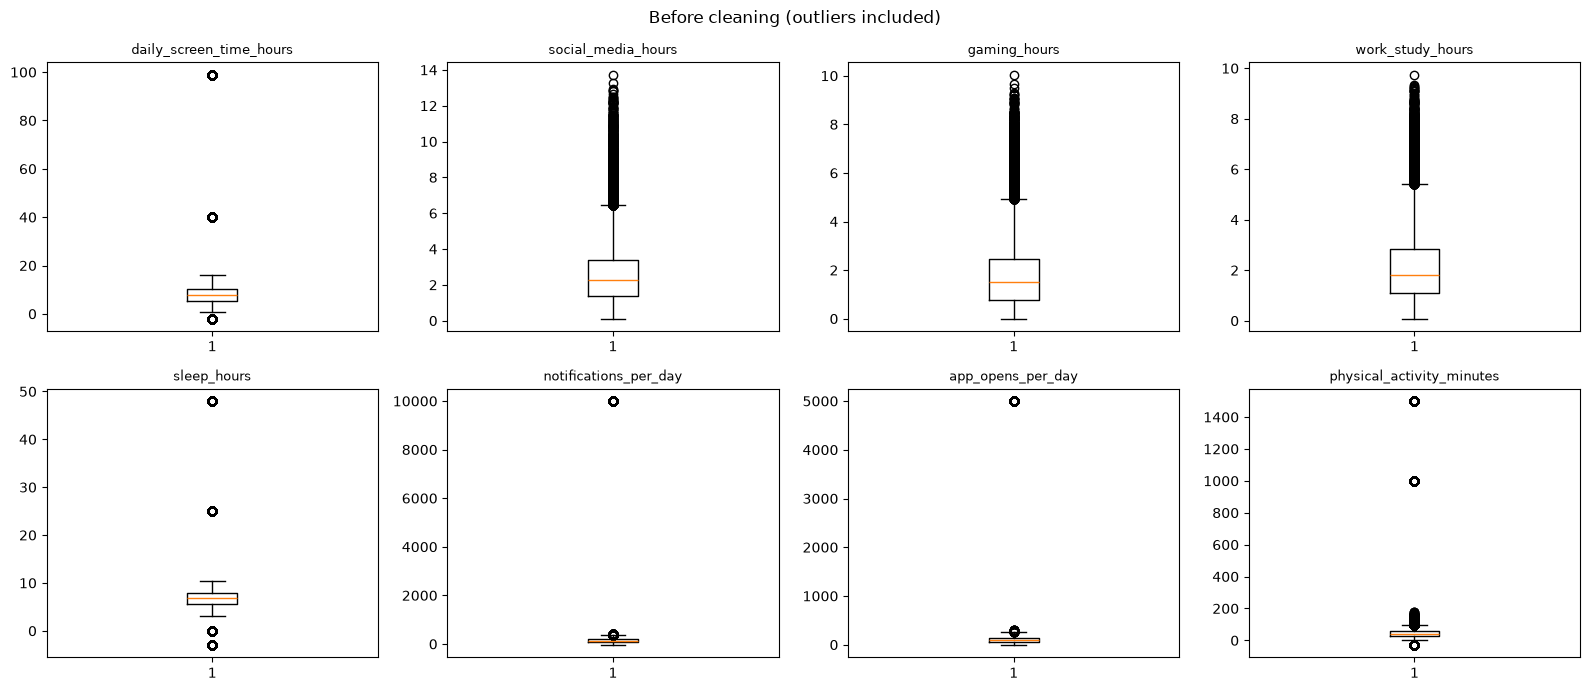

In [21]:
import matplotlib.pyplot as plt

def plot_boxes(data, title):
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    for ax, col in zip(axes.ravel(), num_cols):
        ax.boxplot(data[col].dropna())
        ax.set_title(col, fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_boxes(df, "Before cleaning (outliers included)")

In [22]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    print(col, ": values outside the box limits:", ((df[col] < lower) | (df[col] > upper)).sum())

daily_screen_time_hours : values outside the box limits: 1045
social_media_hours : values outside the box limits: 3546
gaming_hours : values outside the box limits: 6167
work_study_hours : values outside the box limits: 4971
sleep_hours : values outside the box limits: 1045
notifications_per_day : values outside the box limits: 606
app_opens_per_day : values outside the box limits: 594
physical_activity_minutes : values outside the box limits: 4099


In [23]:
print(df[num_cols].lt(0).sum())

daily_screen_time_hours      343
social_media_hours             0
gaming_hours                   0
work_study_hours               0
sleep_hours                  250
notifications_per_day        705
app_opens_per_day            506
physical_activity_minutes    359
dtype: int64


In [24]:
valid_range = {
    "daily_screen_time_hours": (0.5, 16), "social_media_hours": (0, 16),
    "gaming_hours": (0, 16), "work_study_hours": (0, 16), "sleep_hours": (2, 12),
    "notifications_per_day": (0, 1000), "app_opens_per_day": (0, 1000),
    "physical_activity_minutes": (0, 600),
}
for col, (lo, hi) in valid_range.items():
    bad = (df[col] < lo) | (df[col] > hi)
    print(f"{col}: {bad.sum()} outside {lo}-{hi}", df.loc[bad, col].value_counts().head(4).to_dict())
    df.loc[bad, col] = np.nan

daily_screen_time_hours: 1045 outside 0.5-16 {40.0: 361, -2.0: 343, 99.0: 341}
social_media_hours: 0 outside 0-16 {}
gaming_hours: 0 outside 0-16 {}
work_study_hours: 0 outside 0-16 {}
sleep_hours: 1045 outside 2-12 {25.0: 293, 0.0: 268, -3.0: 250, 48.0: 234}
notifications_per_day: 1045 outside 0-1000 {-1.0: 367, 9999.0: 340, -50.0: 338}
app_opens_per_day: 1045 outside 0-1000 {5000.0: 539, -10.0: 506}
physical_activity_minutes: 1045 outside 0-600 {-30.0: 359, 1500.0: 347, 999.0: 339}


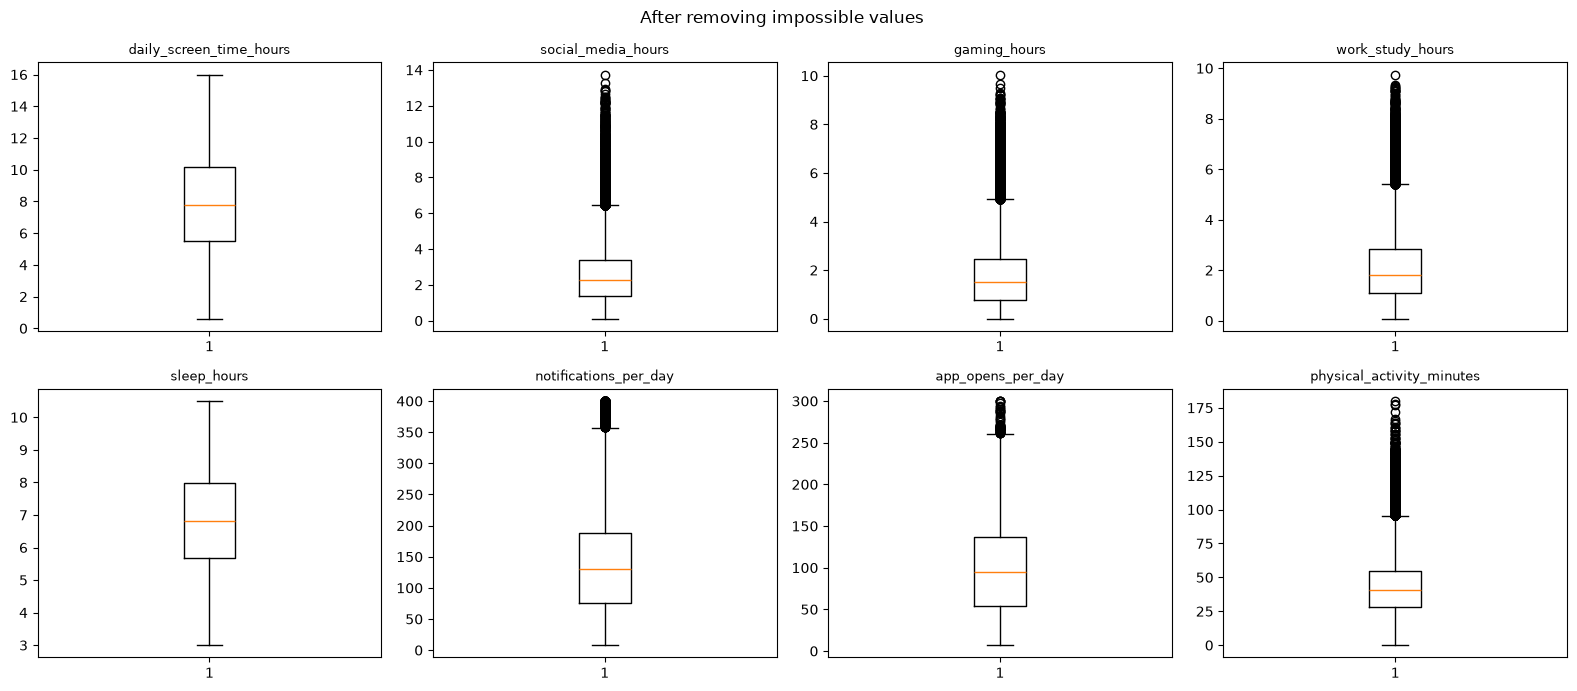

In [25]:
plot_boxes(df, "After removing impossible values")

In [26]:
parts = df[["social_media_hours", "gaming_hours", "work_study_hours"]].sum(axis=1)
bad_total = parts > df["daily_screen_time_hours"]
print("Social + gaming + work/study more than total screen time:", bad_total.sum())
df.loc[bad_total, "daily_screen_time_hours"] = np.nan

too_long = (df["daily_screen_time_hours"] + df["sleep_hours"]) > 22
print("Screen time + sleep more than 22 h:", too_long.sum())
df.loc[too_long, "daily_screen_time_hours"] = np.nan

Social + gaming + work/study more than total screen time: 2426
Screen time + sleep more than 22 h: 0


In [27]:
print(df.isnull().sum()[df.isnull().sum() > 0])
print((df.isnull().sum() / len(df) * 100).round(2)[df.isnull().sum() > 0])

daily_screen_time_hours      6607
social_media_hours           3136
gaming_hours                 3136
work_study_hours             3136
sleep_hours                  4181
notifications_per_day        4181
app_opens_per_day            4181
physical_activity_minutes    4181
dtype: int64
daily_screen_time_hours      2.53
social_media_hours           1.20
gaming_hours                 1.20
work_study_hours             1.20
sleep_hours                  1.60
notifications_per_day        1.60
app_opens_per_day            1.60
physical_activity_minutes    1.60
dtype: float64


In [28]:
df = df.sort_values(["user_id", "day_index"]).reset_index(drop=True)
was_missing = df[num_cols].isnull()

for col in num_cols:
    df[col] = df.groupby("user_id")[col].transform(lambda s: s.interpolate(limit_direction="both"))
    df[col] = df[col].fillna(df.groupby("user_id")[col].transform("median")).fillna(df[col].median())

print(df[num_cols].isnull().sum().sum(), "missing numbers left")

0 missing numbers left


In [29]:
df[hours] = df[hours].round(2)
df[["notifications_per_day", "app_opens_per_day", "physical_activity_minutes"]] = \
    df[["notifications_per_day", "app_opens_per_day", "physical_activity_minutes"]].round(0)

parts = df[["social_media_hours", "gaming_hours", "work_study_hours"]].sum(axis=1)
df["daily_screen_time_hours"] = np.maximum(df["daily_screen_time_hours"], (parts / 0.97).round(2))

print("Components more than total:", (parts > df["daily_screen_time_hours"]).sum())
print("Screen time + sleep more than 22 h:", ((df["daily_screen_time_hours"] + df["sleep_hours"]) > 22.01).sum())

Components more than total: 0
Screen time + sleep more than 22 h: 61


In [30]:
screen, sleep = "daily_screen_time_hours", "sleep_hours"
over = (df[screen] + df[sleep]) > 22
fix_sleep = over & was_missing[sleep] & ~was_missing[screen]
df.loc[fix_sleep, sleep] = (22 - df.loc[fix_sleep, screen]).clip(lower=2).round(2)

over = (df[screen] + df[sleep]) > 22
df.loc[over, screen] = (22 - df.loc[over, sleep]).round(2)

df[screen] = df[screen].clip(upper=16)

comps = ["social_media_hours", "gaming_hours", "work_study_hours"]
parts = df[comps].sum(axis=1)
too_big = parts > df[screen]
factor = 0.97 * df.loc[too_big, screen] / parts[too_big]
for c in comps:
    df.loc[too_big, c] = (df.loc[too_big, c] * factor).round(2)

parts = df[comps].sum(axis=1)
print("Rows adjusted:", fix_sleep.sum() + over.sum() + too_big.sum())
print("Screen time + sleep more than 22 h:", ((df[screen] + df[sleep]) > 22.01).sum())
print("Components more than total:", (parts > df[screen]).sum())

Rows adjusted: 71
Screen time + sleep more than 22 h: 0
Components more than total: 0


In [31]:
print(df[num_cols].agg(["min", "max"]).T)

                            min     max
daily_screen_time_hours    0.66   16.00
social_media_hours         0.11   13.74
gaming_hours               0.00   10.05
work_study_hours           0.08    9.75
sleep_hours                3.00   10.50
notifications_per_day      8.00  400.00
app_opens_per_day          7.00  300.00
physical_activity_minutes  0.00  180.00


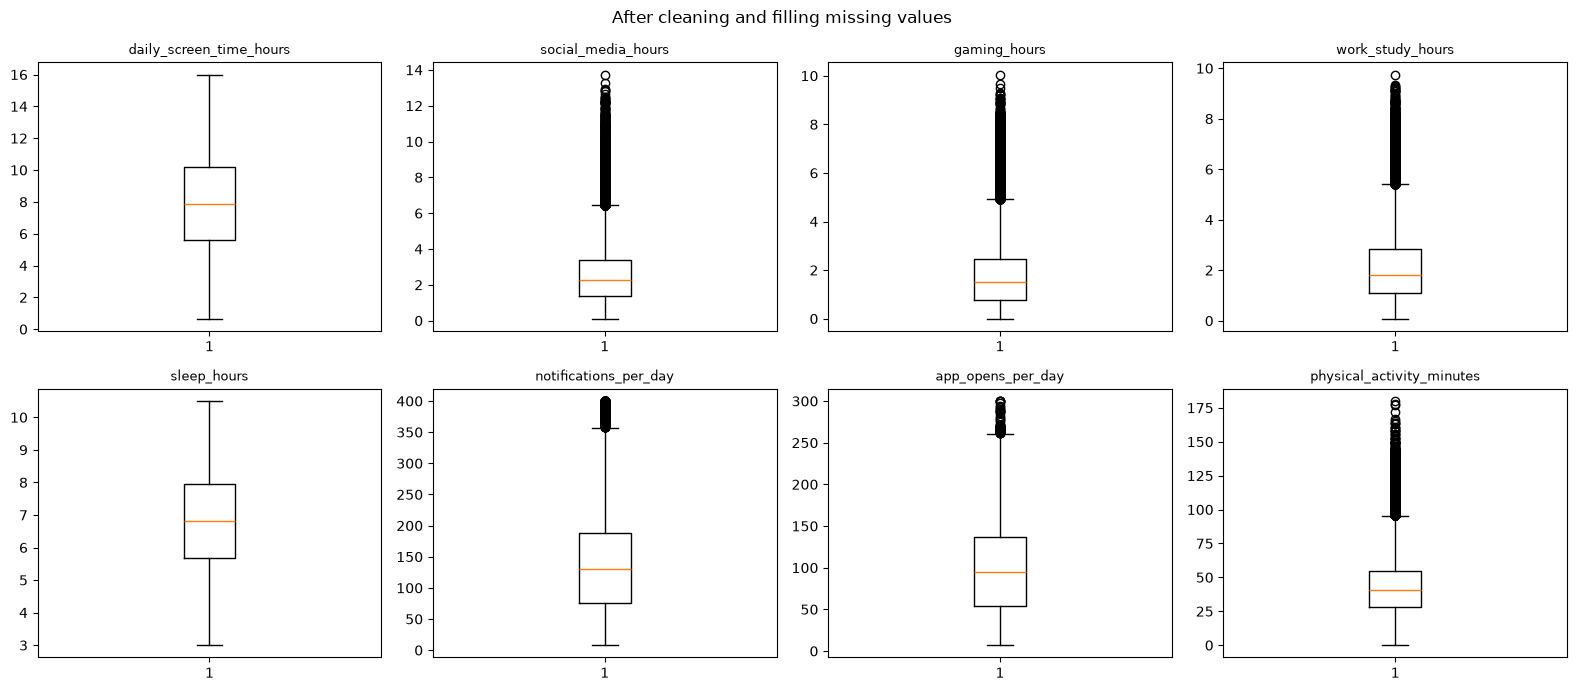

In [32]:
plot_boxes(df, "After cleaning and filling missing values")

In [33]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    print(col, ": values outside the box limits:", ((df[col] < lower) | (df[col] > upper)).sum())

daily_screen_time_hours : values outside the box limits: 0
social_media_hours : values outside the box limits: 3572
gaming_hours : values outside the box limits: 6197
work_study_hours : values outside the box limits: 5005
sleep_hours : values outside the box limits: 0
notifications_per_day : values outside the box limits: 285
app_opens_per_day : values outside the box limits: 55
physical_activity_minutes : values outside the box limits: 3969


In [34]:
print("Rows and columns:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Users:", df["user_id"].nunique())
print("Every user has 30 days:", (df.groupby("user_id").size() == 30).all())
print("One row per user per day:", not df.duplicated(subset=["user_id", "day_index"]).any())
print("Day of week matches date:", (pd.to_datetime(df["date"]).dt.day_name() == df["day_of_week"]).all())
print("Screen time + sleep, maximum:", (df["daily_screen_time_hours"] + df["sleep_hours"]).max().round(2))

Rows and columns: (261390, 14)
Missing values: 0
Duplicate rows: 0
Users: 8713
Every user has 30 days: True
One row per user per day: True
Day of week matches date: True
Screen time + sleep, maximum: 22.0


In [35]:
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 261390 entries, 0 to 261389
Data columns (total 14 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   record_id                  261390 non-null  str    
 1   user_id                    261390 non-null  str    
 2   date                       261390 non-null  str    
 3   day_index                  261390 non-null  int64  
 4   day_of_week                261390 non-null  str    
 5   is_weekend                 261390 non-null  int64  
 6   daily_screen_time_hours    261390 non-null  float64
 7   social_media_hours         261390 non-null  float64
 8   gaming_hours               261390 non-null  float64
 9   work_study_hours           261390 non-null  float64
 10  sleep_hours                261390 non-null  float64
 11  notifications_per_day      261390 non-null  float64
 12  app_opens_per_day          261390 non-null  float64
 13  physical_activity_minutes  261390 non-nu

,record_id,user_id,date,day_index,day_of_week,is_weekend,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,physical_activity_minutes
0,R0000001,U00001,2026-09-01,1,Tuesday,0,2.35,0.63,0.23,1.18,6.90,261.0,151.0,70.0
1,R0000002,U00001,2026-09-02,2,Wednesday,0,2.86,0.67,0.31,1.28,7.66,250.0,145.0,65.0
2,R0000003,U00001,2026-09-03,3,Thursday,0,2.91,0.69,0.32,1.75,7.67,206.0,142.0,62.0
3,R0000004,U00001,2026-09-04,4,Friday,0,2.45,0.66,0.26,1.22,8.18,132.0,123.0,103.0
4,R0000005,U00001,2026-09-05,5,Saturday,1,3.32,0.96,0.48,0.75,7.54,203.0,120.0,99.0
